# EDA 15 · Unsupervised anomaly detection: AE and VAE with anomaly-oriented features

**Hypothesis.** The 20 EDA features fail for anomaly detection because they describe the user's
*current state* in absolute terms — churners and non-churners share similar marginal distributions.
To detect churn as an anomaly, we need features where **non-churners form a tight, predictable
cluster** and **churners fall outside it**.

**Feature redesign principle:**
- Only binary indicators with ratio > 15x (rare in NC, present in C).
- Ratio/decay features: change relative to the user's own previous period (NC ≈ 1.0, C cae).
- Silence/gap features: high in churners, low in NC.
- Dropped features that showed ratio ≤ 1.3x in EDA (has_logs, is_silent_30, has_any_lapse, is_manual_and_silent).

**Feature set (10 total):**
- CAT (2): `state`, `expiry_month`
- BIN (2): `is_cancel_state` (16.8x), `is_lapsed` (15.2x)
- NUM (6): `listening_ratio`, `active_ratio`, `days_since_last_log`, `longest_gap`, `lapse_density`, `n_lapses`

**Protocol.** Same as EDA 09:
- Train AE and VAE on **non-churned fit users** only.
- Reconstruction error = anomaly score.
- Z-dim sweep `{4, 8, 16}`.
- Evaluate on **February tune** (in-distribution) and **March** (out of time).
- Metrics: ROC AUC, AP, F1, Precision, Recall at best-F1 threshold chosen on tune.

## 0. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datetime import date
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, f1_score, precision_score, recall_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

FEB_CUTOFF = date(2017, 1, 31)
MAR_CUTOFF = date(2017, 2, 28)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Z_DIMS = [4, 8, 16]
SEED = C.SEED
torch.manual_seed(SEED)
np.random.seed(SEED)
OUT_DIR = EDA_DIR / "cache" / "nb15"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAT = ["expiry_month"]
BIN = []
NUM = [
    "longest_gap",
    "latest_gap_ratio",
    "renewal_frequency",
    "active_days_90", "active_days_30",
    "active_weeks_90",
]

print(f"device: {DEVICE} | z_dims: {Z_DIMS} | seed: {SEED}")
print(f"features: {len(CAT)} cat + {len(BIN)} bin + {len(NUM)} num = {len(CAT)+len(BIN)+len(NUM)} total")

device: cpu | z_dims: [4, 8, 16] | seed: 110
features: 1 cat + 0 bin + 6 num = 7 total


## 1. Feature engineering

### Feature set final (10 features)

| Feature | Tipo | Señal |
|---|---|---|
| `state` | cat | cancel=82.6% churn, manual=31.8%, auto-renew=2.1% |
| `expiry_month` | cat | lapsed=50.9%, later=40.2%, label_month=5.6% |
| `is_cancel_state` | bin | 16.8x ratio — 14.4% de C, 0.86% NC |
| `is_lapsed` | bin | 15.2x ratio — 11.3% de C, 0.74% NC |
| `listening_ratio` | num | secs_30/(secs_prev30+1): NC≈1.0, C cae hacia 0 |
| `active_ratio` | num | active_days_30/(active_days_prev30+1): mismo decay |
| `days_since_last_log` | num | alto en churners, bajo en NC |
| `longest_gap` | num | alto en churners, bajo en NC |
| `lapse_density` | num | n_lapses/(payer_days/30+1): frecuencia de interrupciones |
| `n_lapses` | num | conteo absoluto de interrupciones de pago |

**Descartadas (EDA mostró ratio ≤ 1.3x):**
`has_logs` (1.0x), `is_manual_and_silent` (81.6x pero 2.2% cobertura),
`is_silent_30` (1.0x), `has_any_lapse` (1.3x)

In [2]:
def _expiry_month(df, cutoff):
    first_label = (pd.Timestamp(cutoff) + pd.Timedelta(days=1)).date()
    nxt   = (pd.Timestamp(first_label) + pd.offsets.MonthBegin(1)).date()
    after = (pd.Timestamp(nxt)         + pd.offsets.MonthBegin(1)).date()
    e = pl.col("last_expire")
    return df.with_columns(
        expiry_month=pl.when(pl.col("expiry_state") == "no txn").then(pl.lit("no txn"))
        .when(e.is_null()).then(pl.lit("unknown"))
        .when(e <= pl.lit(cutoff)).then(pl.lit("lapsed"))
        .when(e < pl.lit(nxt)).then(pl.lit("label month"))
        .when(e < pl.lit(after)).then(pl.lit("next month"))
        .otherwise(pl.lit("later"))
    )


def _full90_listening(users):
    """Días activos, segundos totales y semanas activas sobre la ventana de 90 días."""
    return (
        C.clean_user_days(users)
        .with_columns(week=(pl.col("day") // 7))
        .group_by("msno")
        .agg(
            active_days_90=pl.len(),
            secs_90=pl.col("total_secs").sum(),
            active_weeks_90=pl.col("week").n_unique(),
        )
        .collect(engine="streaming")
    )


def build_features(users, cutoff, keep_methods):
    C.set_cutoff(cutoff)
    txn  = C.clean_transactions(users)
    st   = C.state_block(C.subscription_state(txn, users), keep_methods=keep_methods)
    base = (_expiry_month(st, cutoff)
            .join(C.history_block(txn, users), on="msno")
            .join(C.listening_block(users),    on="msno")
            .join(C.member_block(users),        on="msno")
            .with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730)))

    full90 = _full90_listening(users)

    df = (base
          .join(full90, on="msno", how="left")
          .with_columns(
              pl.col("active_days_90").fill_null(0),
              pl.col("secs_90").fill_null(0.0),
              pl.col("active_weeks_90").fill_null(0),
          )
          .with_columns(
              # --- pago ---
              lapse_density=(
                  pl.col("n_lapses").cast(pl.Float64) /
                  (pl.col("payer_days") / 30.0 + 1.0)
              ),
              renewal_frequency=(
                  pl.col("payer_days").cast(pl.Float64) /
                  (pl.col("n_lapses").cast(pl.Float64) + 1.0)
              ),
              # --- actividad 90d ---
              secs_per_week_90=(
                  pl.col("secs_90").cast(pl.Float64) /
                  (pl.col("active_weeks_90").cast(pl.Float64) + 1.0)
              ),
              latest_gap_ratio=(
                  pl.col("longest_gap").cast(pl.Float64) /
                  (pl.col("active_days_90").cast(pl.Float64) + 1.0)
              ),
          ))

    C.set_cutoff(FEB_CUTOFF)
    return df


# --- Payment method vocabulary (learned on fit only) ---
cohort = C.load_cohort()
C.set_cutoff(FEB_CUTOFF)
_fit_raw   = cohort.filter(pl.col("split") == "fit").select("msno", "is_churn")
_fit_state = C.subscription_state(C.clean_transactions(_fit_raw), _fit_raw)
KEEP_METHODS = (
    _fit_state.group_by("last_payment_method_id").len()
    .filter((pl.col("len") >= 1000) & pl.col("last_payment_method_id").is_not_null())
    ["last_payment_method_id"].to_list()
)

# --- Build feature tables ---
feb_df = build_features(cohort.select("msno", "is_churn"), FEB_CUTOFF, KEEP_METHODS)
feb_df = feb_df.with_columns(
    pl.Series("split", cohort["split"].to_numpy()),
    pl.Series("y",     cohort["is_churn"].to_numpy()),
)

mar_users = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno", "is_churn"])
mar_df    = build_features(mar_users, MAR_CUTOFF, KEEP_METHODS)
mar_df    = mar_df.with_columns(pl.Series("y", mar_users["is_churn"].to_numpy()))
y_mar     = mar_df["y"].to_numpy()

print(f"Feb rows: {feb_df.height:,}  |  Mar rows: {mar_df.height:,}")
print(f"Feb churn: {feb_df['y'].mean():.2%}  |  Mar churn: {y_mar.mean():.2%}")
feb_df.group_by("split").agg(pl.len().alias("n"), pl.col("y").mean().alias("churn_rate")).sort("split")

Feb rows: 992,931  |  Mar rows: 970,960
Feb churn: 6.39%  |  Mar churn: 8.99%


split,n,churn_rate
str,u32,f64
"""fit""",744699,0.063924
"""stop""",124117,0.063924
"""tune""",124115,0.063917


In [3]:
# ── Distribución de state en todo Febrero ────────────────────────────────────
total_feb = feb_df.height
churn_feb = int(feb_df["y"].sum())
nc_feb    = total_feb - churn_feb

print(f"{'─'*55}")
print(f"TOTAL FEBRERO:   {total_feb:>10,}   churn={churn_feb/total_feb:.2%}")
print(f"  Non-churn:     {nc_feb:>10,}   ({nc_feb/total_feb:.2%})")
print(f"  Churn:         {churn_feb:>10,}   ({churn_feb/total_feb:.2%})")
print(f"{'─'*55}")

state_stats = (
    feb_df
    .group_by("state")
    .agg(
        n=pl.len(),
        churn_n=pl.col("y").sum(),
    )
    .with_columns(
        nc_n=(pl.col("n") - pl.col("churn_n")),
        churn_rate=pl.col("churn_n") / pl.col("n"),
        pct_of_total=pl.col("n") / total_feb,
        pct_of_all_churners=pl.col("churn_n") / churn_feb,
    )
    .sort("churn_rate", descending=True)
)

print(f"\n{'state':<20} {'n':>8} {'pct_total':>10} {'nc_n':>8} {'churn_n':>8} {'churn_rate':>11} {'% churners':>11}")
print("─" * 82)
for row in state_stats.iter_rows(named=True):
    print(f"{str(row['state']):<20} {row['n']:>8,} {row['pct_of_total']:>10.2%} "
          f"{row['nc_n']:>8,} {row['churn_n']:>8,} {row['churn_rate']:>10.1%} "
          f"{row['pct_of_all_churners']:>10.1%}")

manual_n      = int(state_stats.filter(pl.col("state") == "manual")["n"][0])
manual_churn  = int(state_stats.filter(pl.col("state") == "manual")["churn_n"][0])
manual_nc     = manual_n - manual_churn
print(f"\n{'─'*55}")
print(f"SEGMENTO MANUAL:")
print(f"  Total:         {manual_n:>10,}   ({manual_n/total_feb:.2%} del total Feb)")
print(f"  Non-churn:     {manual_nc:>10,}   ({manual_nc/manual_n:.2%} dentro del segmento)")
print(f"  Churn:         {manual_churn:>10,}   ({manual_churn/manual_n:.2%} dentro del segmento)")
print(f"  Cubre:         {manual_churn/churn_feb:.2%} de todos los churners de Feb")
print(f"{'─'*55}")

───────────────────────────────────────────────────────
TOTAL FEBRERO:      992,931   churn=6.39%
  Non-churn:        929,460   (93.61%)
  Churn:             63,471   (6.39%)
───────────────────────────────────────────────────────

state                       n  pct_total     nc_n  churn_n  churn_rate  % churners
──────────────────────────────────────────────────────────────────────────────────
cancel                  9,075      0.91%    1,617    7,458      82.2%      11.8%
manual                110,846     11.16%   75,622   35,224      31.8%      55.5%
no txn                  2,095      0.21%    1,434      661      31.6%       1.0%
cancel + payment        8,152      0.82%    6,471    1,681      20.6%       2.6%
auto-renew            862,763     86.89%  844,316   18,447       2.1%      29.1%

───────────────────────────────────────────────────────
SEGMENTO MANUAL:
  Total:            110,846   (11.16% del total Feb)
  Non-churn:         75,622   (68.22% dentro del segmento)
  Churn:   

## 2. Validate feature distributions: churners vs non-churners

Before training, verify that the new features show clearer separation between classes.
This is the prerequisite for anomaly detection to work.

In [4]:
fit_df = feb_df.filter(pl.col("split") == "fit")
y_fit  = fit_df["y"].to_numpy()

# EDA visual usa solo el segmento manual (110,846 usuarios)
manual_pd = feb_df.filter(pl.col("state") == "manual").to_pandas()
y_manual  = manual_pd["y"].to_numpy()

print(f"Segmento manual — total: {len(manual_pd):,}  |  "
      f"churn: {y_manual.sum():,} ({y_manual.mean():.2%})  |  "
      f"non-churn: {(y_manual==0).sum():,} ({(y_manual==0).mean():.2%})")
print()

print("=== Binary sparse indicators — segmento manual ===")
print(f"{'Feature':<25}  {'non-churn':>10}  {'churn':>10}  {'ratio':>8}")
print("-" * 60)
for col in BIN:
    vals = manual_pd[col].values
    nc   = vals[y_manual == 0].mean()
    c    = vals[y_manual == 1].mean()
    print(f"{col:<25}  {nc:>10.2%}  {c:>10.2%}  {c/(nc+1e-9):>7.1f}x")

print()
print("=== Numeric features — segmento manual (median por clase) ===")
print(f"{'Feature':<25}  {'non-churn':>12}  {'churn':>12}")
print("-" * 55)
for col in NUM:
    vals = manual_pd[col].fillna(0).to_numpy()
    nc   = np.median(vals[y_manual == 0])
    c    = np.median(vals[y_manual == 1])
    print(f"{col:<25}  {nc:>12.4f}  {c:>12.4f}")

Segmento manual — total: 110,846  |  churn: 35,224 (31.78%)  |  non-churn: 75,622 (68.22%)

=== Binary sparse indicators — segmento manual ===
Feature                     non-churn       churn     ratio
------------------------------------------------------------

=== Numeric features — segmento manual (median por clase) ===
Feature                       non-churn         churn
-------------------------------------------------------
longest_gap                      6.0000       14.0000
latest_gap_ratio                 0.1034        0.3600
renewal_frequency               47.5714       66.3636
active_days_90                  62.0000       41.0000
active_days_30                  22.0000       16.0000
active_weeks_90                 13.0000       11.0000


### 2b. EDA de distribución por clase

Para cada feature: qué % de usuarios con ese valor son churn, y qué % del total de churners/no-churners tiene ese valor.

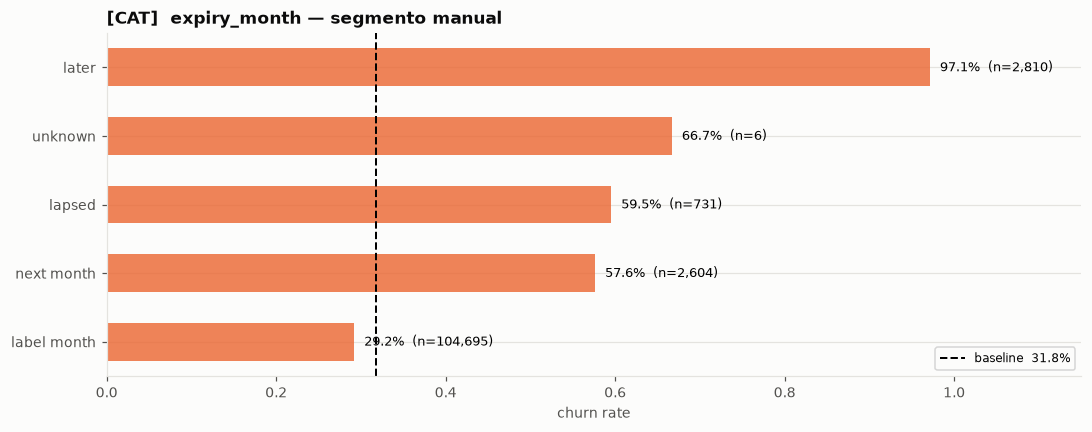

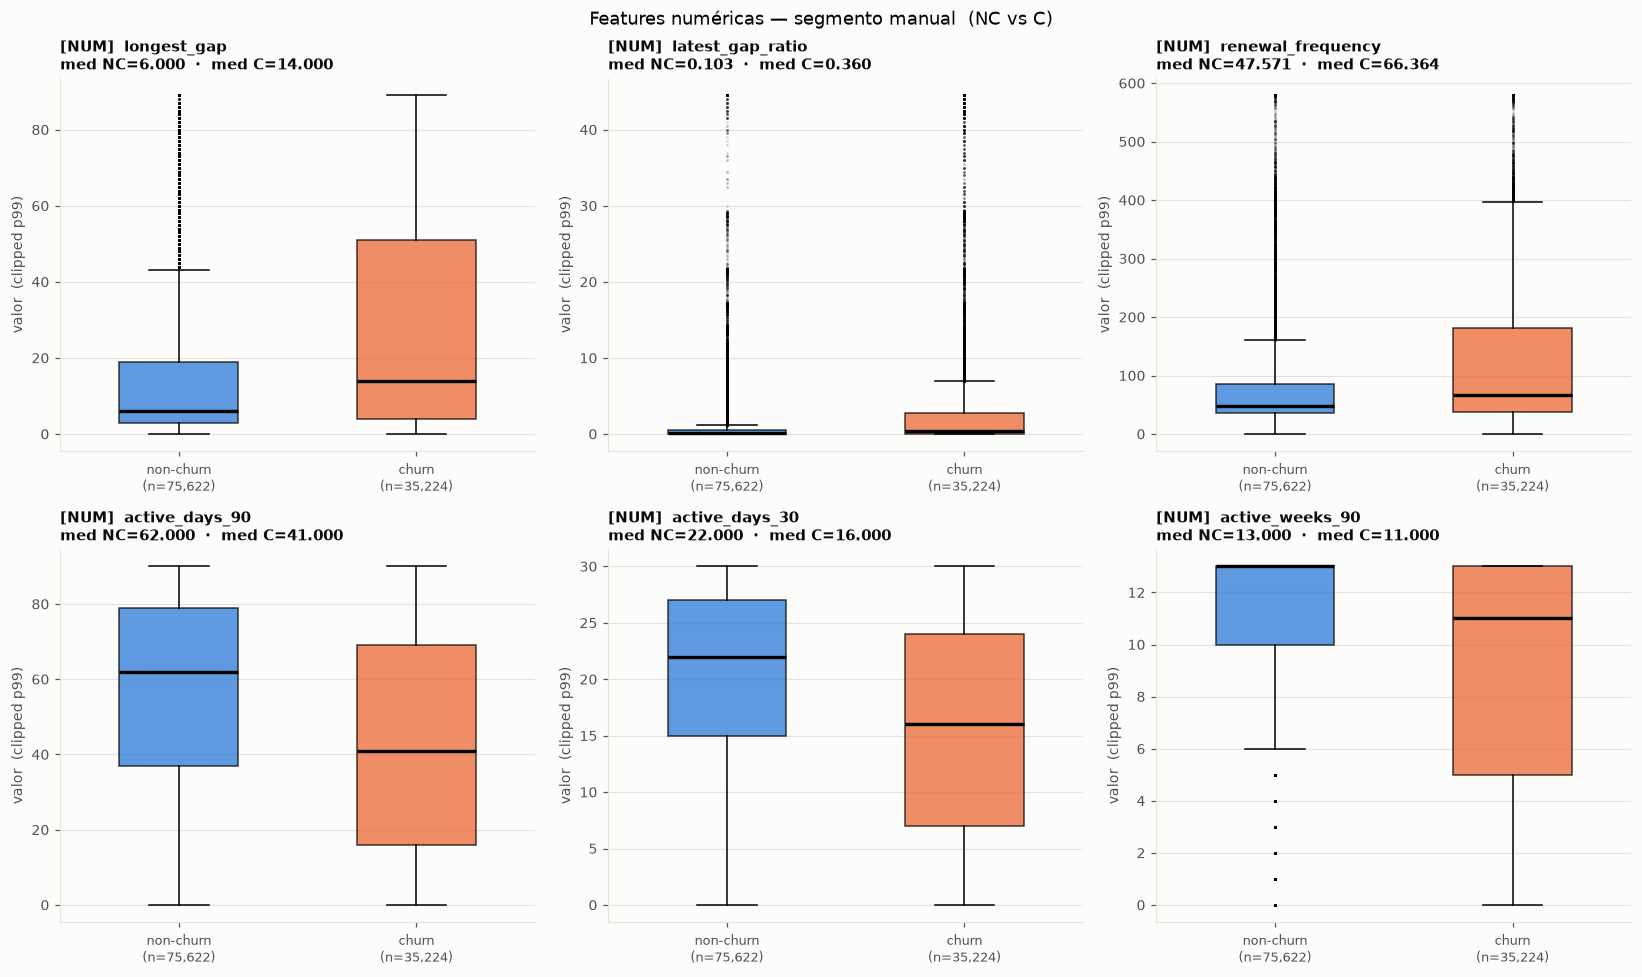

In [5]:
import math
baseline = y_manual.mean()

# ── CAT — expiry_month (state es constante = 'manual') ───────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ct = (manual_pd.groupby("expiry_month")["y"]
      .agg(churn_n="sum", total="count")
      .assign(churn_rate=lambda d: d["churn_n"] / d["total"])
      .sort_values("churn_rate"))
colors = [C.COLORS["churn"] if r > 0.15 else C.COLORS["stay"] for r in ct["churn_rate"]]
bars = ax.barh(ct.index.astype(str), ct["churn_rate"], color=colors, alpha=0.82, height=0.55)
for bar, (_, row) in zip(bars, ct.iterrows()):
    ax.text(bar.get_width() + 0.012, bar.get_y() + bar.get_height() / 2,
            f"{row.churn_rate:.1%}  (n={int(row.total):,})", va="center", fontsize=8.5)
ax.axvline(baseline, color="black", ls="--", lw=1.3, label=f"baseline  {baseline:.1%}")
ax.set_xlabel("churn rate")
ax.set_title("[CAT]  expiry_month — segmento manual", loc="left", fontsize=11, fontweight="bold")
ax.set_xlim(0, 1.15)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ── BIN — una barra por feature (0 vs 1) ─────────────────────────────────────
if BIN:
    n_bin = len(BIN)
    fig, axes = plt.subplots(1, n_bin, figsize=(5 * n_bin, 4))
    if n_bin == 1:
        axes = [axes]
    for ax, col in zip(axes, BIN):
        for val, label, color in [(0, "0  (ausente)", C.COLORS["stay"]),
                                   (1, "1  (presente)", C.COLORS["churn"])]:
            mask = manual_pd[col] == val
            n  = int(mask.sum())
            cr = float(manual_pd.loc[mask, "y"].mean()) if n > 0 else 0.0
            bar = ax.bar(label, cr, color=color, alpha=0.82, width=0.45)
            ax.text(bar[0].get_x() + bar[0].get_width() / 2,
                    cr + 0.018, f"{cr:.1%}\n(n={n:,})",
                    ha="center", va="bottom", fontsize=9)
        ax.axhline(baseline, color="black", ls="--", lw=1.3, label=f"baseline  {baseline:.1%}")
        ax.set_ylabel("churn rate")
        ax.set_ylim(0, 1.05)
        ax.set_title(f"[BIN]  {col}", loc="left", fontsize=11, fontweight="bold")
        ax.legend(fontsize=8)
    plt.suptitle("Features binarias — segmento manual", fontsize=12)
    plt.tight_layout()
    plt.show()

# ── NUM — boxplots NC vs C (grid dinámico) ────────────────────────────────────
n_num  = len(NUM)
n_cols = 3
n_rows = math.ceil(n_num / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = axes.flatten()
for ax, col in zip(axes, NUM):
    cap = float(manual_pd[col].quantile(0.99))
    nc  = manual_pd.loc[y_manual == 0, col].fillna(0).clip(upper=cap).values
    c   = manual_pd.loc[y_manual == 1, col].fillna(0).clip(upper=cap).values
    bp  = ax.boxplot(
        [nc, c],
        patch_artist=True,
        medianprops=dict(color="black", lw=2.2),
        flierprops=dict(marker=".", markersize=1.5, alpha=0.15),
        widths=0.5,
    )
    bp["boxes"][0].set_facecolor(C.COLORS["stay"]);  bp["boxes"][0].set_alpha(0.75)
    bp["boxes"][1].set_facecolor(C.COLORS["churn"]); bp["boxes"][1].set_alpha(0.75)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f"non-churn\n(n={len(nc):,})", f"churn\n(n={len(c):,})"], fontsize=8.5)
    med_nc = float(np.median(nc))
    med_c  = float(np.median(c))
    ax.set_title(f"[NUM]  {col}\nmed NC={med_nc:.3f}  ·  med C={med_c:.3f}",
                 loc="left", fontsize=9.5, fontweight="bold")
    ax.set_ylabel("valor  (clipped p99)")
for ax in axes[n_num:]:
    ax.set_visible(False)
plt.suptitle("Features numéricas — segmento manual  (NC vs C)", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Preprocessing

Fit exclusively on **non-churned fit users**.
- **Categoricals** (`state`, `expiry_month`): integer codes, vocabulary from fit_normal.
- **Binary + Numeric**: `StandardScaler` (binary 0/1 values scale to ≈ ±1; nulls → column mean).

In [6]:
class AnomalyPreprocessor:
    """Fits on non-churned fit users. Categoricals → integer codes. BIN+NUM → StandardScaler."""

    def __init__(self, cat_cols, num_cols):
        self.cat_cols = cat_cols
        self.num_cols = num_cols

    def fit(self, df: pl.DataFrame):
        self.vocabs = {}
        for col in self.cat_cols:
            vals = sorted(v for v in df[col].unique().to_list() if v is not None)
            self.vocabs[col] = {v: i + 1 for i, v in enumerate(vals)}  # 0 = unknown
        self.cat_cardinalities = [len(v) + 1 for v in self.vocabs.values()]

        num_pd = df.select(self.num_cols).to_pandas().infer_objects()
        self.col_means_ = num_pd.mean()
        self.scaler_    = StandardScaler()
        self.scaler_.fit(num_pd.fillna(self.col_means_).values.astype(float))
        self.numeric_dim = len(self.num_cols)
        return self

    def transform(self, df: pl.DataFrame):
        cat_arrs = []
        for col in self.cat_cols:
            vocab = self.vocabs[col]
            codes = df[col].to_pandas().map(lambda v: vocab.get(v, 0)).fillna(0).astype(int)
            cat_arrs.append(codes.values)
        x_cat = np.stack(cat_arrs, axis=1)

        num_pd = df.select(self.num_cols).to_pandas().infer_objects().fillna(self.col_means_)
        x_num  = self.scaler_.transform(num_pd.values.astype(float))

        return (torch.tensor(x_num, dtype=torch.float32),
                torch.tensor(x_cat, dtype=torch.long))


ALL_NUM = BIN + NUM

# ── Entrenamiento: NC del segmento manual de febrero ─────────────────────────
fit_normal_df  = feb_df.filter(
    (pl.col("split") == "fit") & (pl.col("y") == 0) & (pl.col("state") == "manual")
)
stop_normal_df = feb_df.filter(
    (pl.col("split") == "stop") & (pl.col("y") == 0) & (pl.col("state") == "manual")
)

prep = AnomalyPreprocessor(CAT, ALL_NUM)
prep.fit(fit_normal_df)

x_num_fit_n,  x_cat_fit_n  = prep.transform(fit_normal_df)
x_num_stop_n, x_cat_stop_n = prep.transform(stop_normal_df)

# ── Testeo: segmento manual de marzo (OOT) ────────────────────────────────────
mar_man_df = mar_df.filter(pl.col("state") == "manual")
x_num_mar_man, x_cat_mar_man = prep.transform(mar_man_df)

SCENARIOS = [
    ("Mar · manual", x_num_mar_man, x_cat_mar_man, mar_man_df["y"].to_numpy()),
]

print(f"Entrenamiento  — fit NC manual:  {fit_normal_df.height:>7,}  |  stop NC manual: {stop_normal_df.height:>7,}")
print(f"Test           — mar manual:     {mar_man_df.height:>7,}  |  churn: {mar_man_df['y'].mean():.2%}")
print(f"\ncat_cardinalities: {prep.cat_cardinalities}")
print(f"numeric_dim: {prep.numeric_dim}")

Entrenamiento  — fit NC manual:   56,699  |  stop NC manual:   9,551
Test           — mar manual:     113,048  |  churn: 40.74%

cat_cardinalities: [6]
numeric_dim: 6


## 4. Model architectures (AE and VAE)

In [7]:
class _Encoder(nn.Module):
    def __init__(self, numeric_dim, cat_cardinalities, hidden_dims, z_dim, variational):
        super().__init__()
        self.variational = variational
        self.embeddings  = nn.ModuleList([
            nn.Embedding(card, max(2, -(-card // 3)))
            for card in cat_cardinalities
        ])
        emb_total = sum(max(2, -(-c // 3)) for c in cat_cardinalities)
        in_dim    = numeric_dim + emb_total
        layers    = []
        for h in hidden_dims:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU()]
            in_dim  = h
        self.mlp     = nn.Sequential(*layers)
        self.mu_head = nn.Linear(in_dim, z_dim)
        if variational:
            self.lv_head = nn.Linear(in_dim, z_dim)

    def forward(self, x_num, x_cat):
        embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        h    = self.mlp(torch.cat([x_num] + embs, dim=1))
        mu   = self.mu_head(h)
        if self.variational:
            return mu, self.lv_head(h)
        return mu


class _Decoder(nn.Module):
    def __init__(self, z_dim, hidden_dims, numeric_dim, cat_cardinalities):
        super().__init__()
        layers, in_dim = [], z_dim
        for h in reversed(hidden_dims):
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU()]
            in_dim  = h
        self.mlp       = nn.Sequential(*layers)
        self.num_head  = nn.Linear(in_dim, numeric_dim)
        self.cat_heads = nn.ModuleList([nn.Linear(in_dim, c) for c in cat_cardinalities])

    def forward(self, z):
        h = self.mlp(z)
        return self.num_head(h), [head(h) for head in self.cat_heads]


class AE(nn.Module):
    def __init__(self, numeric_dim, cat_cardinalities, z_dim, hidden_dims=(64, 32)):
        super().__init__()
        self.enc = _Encoder(numeric_dim, cat_cardinalities, hidden_dims, z_dim, variational=False)
        self.dec = _Decoder(z_dim, hidden_dims, numeric_dim, cat_cardinalities)

    def forward(self, x_num, x_cat):
        z = self.enc(x_num, x_cat)
        num_recon, cat_logits = self.dec(z)
        return z, num_recon, cat_logits

    def encode(self, x_num, x_cat):
        return self.enc(x_num, x_cat)


class VAE(nn.Module):
    def __init__(self, numeric_dim, cat_cardinalities, z_dim, hidden_dims=(64, 32)):
        super().__init__()
        self.enc = _Encoder(numeric_dim, cat_cardinalities, hidden_dims, z_dim, variational=True)
        self.dec = _Decoder(z_dim, hidden_dims, numeric_dim, cat_cardinalities)

    def forward(self, x_num, x_cat):
        mu, lv = self.enc(x_num, x_cat)
        z = mu + (torch.randn_like(mu) * torch.exp(0.5 * lv)) if self.training else mu
        num_recon, cat_logits = self.dec(z)
        return z, mu, lv, num_recon, cat_logits

    def encode(self, x_num, x_cat):
        mu, _ = self.enc(x_num, x_cat)
        return mu


_demo   = AE(prep.numeric_dim, prep.cat_cardinalities, z_dim=8)
n_params = sum(p.numel() for p in _demo.parameters())
print(f"AE parameter count (z=8): {n_params:,}  |  input_dim ≈ {prep.numeric_dim} num + embeddings")

AE parameter count (z=8): 6,496  |  input_dim ≈ 6 num + embeddings


## 5. Training utilities

In [8]:
def _recon_loss(x_num, x_cat, num_recon, cat_logits):
    num = F.mse_loss(num_recon, x_num)
    cat = sum(F.cross_entropy(logits, x_cat[:, i]) for i, logits in enumerate(cat_logits))
    return num + cat


def per_sample_error(model, x_num, x_cat, device=DEVICE, batch=4096, is_vae=False):
    model.eval()
    parts = []
    with torch.no_grad():
        for i in range(0, len(x_num), batch):
            bn, bc = x_num[i:i+batch].to(device), x_cat[i:i+batch].to(device)
            if is_vae:
                _, _, _, nr, cl = model(bn, bc)
            else:
                _, nr, cl = model(bn, bc)
            ne = F.mse_loss(nr, bn, reduction="none").sum(dim=1)
            ce = sum(F.cross_entropy(lg, bc[:, k], reduction="none") for k, lg in enumerate(cl))
            parts.append((ne + ce).cpu())
    return torch.cat(parts).numpy()


def encode_all(model, x_num, x_cat, device=DEVICE, batch=4096):
    model.eval()
    parts = []
    with torch.no_grad():
        for i in range(0, len(x_num), batch):
            bn, bc = x_num[i:i+batch].to(device), x_cat[i:i+batch].to(device)
            parts.append(model.encode(bn, bc).cpu())
    return torch.cat(parts).numpy()


def train(model, xn_tr, xc_tr, xn_val, xc_val,
          epochs=80, batch=4096, lr=1e-3, patience=12,
          is_vae=False, beta=0.5, device=DEVICE, verbose_every=10):
    model.to(device)
    opt  = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    n    = len(xn_tr)
    best, best_state, wait = float("inf"), None, 0
    history = []

    for ep in range(1, epochs + 1):
        model.train()
        idx, tr_loss = torch.randperm(n), 0.0
        for i in range(0, n, batch):
            bi = idx[i:i+batch]
            bn, bc = xn_tr[bi].to(device), xc_tr[bi].to(device)
            opt.zero_grad()
            if is_vae:
                _, mu, lv, nr, cl = model(bn, bc)
                recon = _recon_loss(bn, bc, nr, cl)
                kl    = -0.5 * torch.mean(1 + lv - mu.pow(2) - lv.exp())
                loss  = recon + beta * kl
            else:
                _, nr, cl = model(bn, bc)
                loss = _recon_loss(bn, bc, nr, cl)
            loss.backward()
            opt.step()
            tr_loss += loss.item() * len(bi)

        model.eval()
        with torch.no_grad():
            vn, vc = xn_val.to(device), xc_val.to(device)
            if is_vae:
                _, mu, lv, nr, cl = model(vn, vc)
                recon = _recon_loss(vn, vc, nr, cl)
                kl    = -0.5 * torch.mean(1 + lv - mu.pow(2) - lv.exp())
                val   = (recon + beta * kl).item()
            else:
                _, nr, cl = model(vn, vc)
                val = _recon_loss(vn, vc, nr, cl).item()

        history.append({"epoch": ep, "train": tr_loss / n, "val": val})
        if val < best:
            best, best_state, wait = val, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
        if ep % verbose_every == 0 or ep == 1:
            print(f"  epoch {ep:3d}  train={tr_loss/n:.5f}  val={val:.5f}")

    model.load_state_dict(best_state)
    best_ep = history[np.argmin([r["val"] for r in history])]["epoch"]
    print(f"  → best val={best:.5f} at epoch {best_ep}")
    return pd.DataFrame(history)


print("Training utilities ready.")

Training utilities ready.


## 6. Z-dim sweep — AE and VAE

In [9]:
ae_results, vae_results = {}, {}
ae_models,  vae_models  = {}, {}

for z in Z_DIMS:
    print(f"\n{'='*50}\n  AE   z_dim={z}\n{'='*50}")
    torch.manual_seed(SEED)
    ae = AE(prep.numeric_dim, prep.cat_cardinalities, z_dim=z)
    ae_results[z] = train(ae, x_num_fit_n, x_cat_fit_n, x_num_stop_n, x_cat_stop_n)
    ae_models[z]  = ae
    torch.save(ae.state_dict(), OUT_DIR / f"ae_z{z}.pt")

    print(f"\n{'='*50}\n  VAE  z_dim={z}\n{'='*50}")
    torch.manual_seed(SEED)
    vae = VAE(prep.numeric_dim, prep.cat_cardinalities, z_dim=z)
    vae_results[z] = train(vae, x_num_fit_n, x_cat_fit_n, x_num_stop_n, x_cat_stop_n, is_vae=True)
    vae_models[z]  = vae
    torch.save(vae.state_dict(), OUT_DIR / f"vae_z{z}.pt")

print("\nSweep complete.")


  AE   z_dim=4
  epoch   1  train=2.06818  val=2.43994
  epoch  10  train=0.11033  val=0.10262
  epoch  20  train=0.04780  val=0.04590
  epoch  30  train=0.03178  val=0.03130
  epoch  40  train=0.02288  val=0.02177
  epoch  50  train=0.01871  val=0.01637
  epoch  60  train=0.01322  val=0.01222
  epoch  70  train=0.01209  val=0.01110
  epoch  80  train=0.01109  val=0.00957
  → best val=0.00957 at epoch 80

  VAE  z_dim=4
  epoch   1  train=2.34381  val=2.31500
  epoch  10  train=0.53125  val=0.40962
  epoch  20  train=0.44718  val=0.34337
  epoch  30  train=0.41740  val=0.32145
  epoch  40  train=0.40525  val=0.31319
  epoch  50  train=0.39724  val=0.30844
  epoch  60  train=0.39236  val=0.30842
  epoch  70  train=0.38775  val=0.30472
  epoch  80  train=0.38378  val=0.30231
  → best val=0.29891 at epoch 79

  AE   z_dim=8
  epoch   1  train=2.19519  val=2.50782
  epoch  10  train=0.08354  val=0.07665
  epoch  20  train=0.03392  val=0.03140
  epoch  30  train=0.02195  val=0.01984
  epoc

## 7. Z-dim summary and best model selection

In [10]:
rows = []
for name, results in [("AE", ae_results), ("VAE", vae_results)]:
    for z, hist in results.items():
        best = hist.loc[hist["val"].idxmin()]
        rows.append({"model": name, "z_dim": z,
                     "best_epoch": int(best["epoch"]),
                     "val_loss":   round(float(best["val"]),   5),
                     "train_loss": round(float(best["train"]), 5)})
summary = pd.DataFrame(rows).set_index(["model", "z_dim"])
print(summary)

BEST_Z_AE  = int(summary.loc["AE"]["val_loss"].idxmin())
BEST_Z_VAE = int(summary.loc["VAE"]["val_loss"].idxmin())
best_ae    = ae_models[BEST_Z_AE]
best_vae   = vae_models[BEST_Z_VAE]
print(f"\nBest AE  z_dim={BEST_Z_AE}  |  Best VAE z_dim={BEST_Z_VAE}")

             best_epoch  val_loss  train_loss
model z_dim                                  
AE    4              80   0.00957     0.01109
      8              76   0.00597     0.00734
      16             76   0.00441     0.00591
VAE   4              79   0.29891     0.38351
      8              80   0.20282     0.25200
      16             80   0.13590     0.16693

Best AE  z_dim=16  |  Best VAE z_dim=16


## 8. Anomaly scores and error gap

The key diagnostic: does the mean error gap between churners and non-churners increase
compared to the original 20 features? A larger gap means the AE separates the classes better.

In [11]:
scores = {}
for model_name, model, is_vae in [("AE", best_ae, False), ("VAE", best_vae, True)]:
    scores[model_name] = {}
    for label, xn, xc, _ in SCENARIOS:
        scores[model_name][label] = per_sample_error(model, xn, xc, is_vae=is_vae)

print(f"{'Model':<6}  {'Escenario':<18}  {'NC mean':>10}  {'C mean':>10}  {'Gap ratio':>10}")
print("─" * 62)
for model_name in ["AE", "VAE"]:
    for label, _, _, y in SCENARIOS:
        err = scores[model_name][label]
        mn  = err[y == 0].mean()
        mc  = err[y == 1].mean()
        print(f"{model_name:<6}  {label:<18}  {mn:>10.4f}  {mc:>10.4f}  {mc/mn:>9.2f}x")

Model   Escenario              NC mean      C mean   Gap ratio
──────────────────────────────────────────────────────────────
AE      Mar · manual            0.0193      0.1006       5.21x
VAE     Mar · manual            0.1738      0.3237       1.86x


## 9. Error distribution: churn vs normal

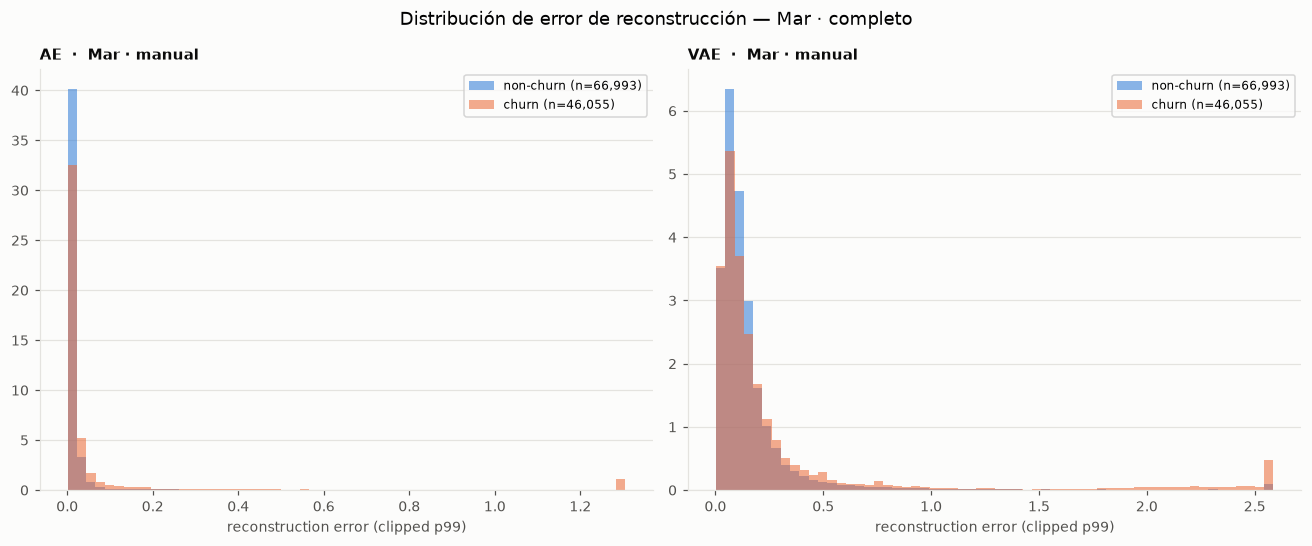

In [12]:
label, _, _, y = SCENARIOS[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model_name in zip(axes, ["AE", "VAE"]):
    err = scores[model_name][label]
    cap = np.percentile(err, 99)
    for lbl, lname, color in [
        (0, "non-churn", C.COLORS["stay"]),
        (1, "churn",     C.COLORS["churn"]),
    ]:
        ax.hist(np.clip(err[y == lbl], 0, cap), bins=60, alpha=0.55, density=True,
                label=f"{lname} (n={int((y==lbl).sum()):,})", color=color)
    ax.set_xlabel("reconstruction error (clipped p99)")
    ax.set_title(f"{model_name}  ·  {label}", loc="left", fontsize=10)
    ax.legend(fontsize=8)

plt.suptitle("Distribución de error de reconstrucción — Mar · completo", fontsize=12)
plt.tight_layout()
C.save_fig(fig, "15_error_distribution")
plt.show()

## 10. Evaluation: F1, Precision, Recall, ROC AUC

Threshold chosen on **Feb tune** (best F1). Applied unchanged to March.

In [13]:
def _best_f1_thr(y, s):
    p, r, t = precision_recall_curve(y, s)
    denom   = p[:-1] + r[:-1]
    f1      = np.where(denom > 0, 2 * p[:-1] * r[:-1] / denom, 0.0)
    return float(t[np.argmax(f1)])


def _eval(err, y, thr, model_name, label):
    yp = (err >= thr).astype(int)
    return {
        "model":        model_name,
        "escenario":    label,
        "roc_auc":      float(roc_auc_score(y, err)),
        "avg_prec":     float(average_precision_score(y, err)),
        "f1":           float(f1_score(y, yp, zero_division=0)),
        "precision":    float(precision_score(y, yp, zero_division=0)),
        "recall":       float(recall_score(y, yp, zero_division=0)),
        "threshold":    round(thr, 4),
        "n_flagged":    int(yp.sum()),
        "n_total":      int(len(y)),
        "flag_rate":    float(yp.mean()),
    }


# Umbral elegido sobre el propio conjunto de marzo (best-F1)
eval_rows = []
for model_name in ["AE", "VAE"]:
    label, _, _, y = SCENARIOS[0]
    thr = _best_f1_thr(y, scores[model_name][label])
    eval_rows.append(_eval(scores[model_name][label], y, thr, model_name, label))

results_df = pd.DataFrame(eval_rows)
results_df.to_csv(OUT_DIR / "results.csv", index=False)

SHOW = ["model", "escenario", "roc_auc", "avg_prec", "f1", "precision", "recall", "flag_rate"]
print(results_df[SHOW].round(4).to_string(index=False))

model    escenario  roc_auc  avg_prec     f1  precision  recall  flag_rate
   AE Mar · manual   0.6538    0.5797 0.5970     0.4569  0.8612     0.7679
  VAE Mar · manual   0.5573    0.4985 0.5789     0.4074  1.0000     0.9999


## 11. Precision-Recall curves

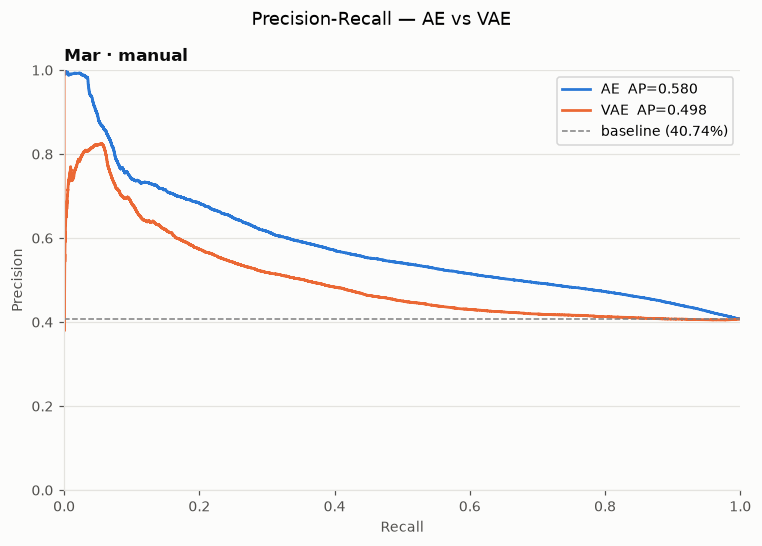

In [14]:
label, _, _, y = SCENARIOS[0]
baseline = float(y.mean())

fig, ax = plt.subplots(figsize=(7, 5))
for model_name, color in [("AE", C.COLORS["stay"]), ("VAE", C.COLORS["churn"])]:
    err = scores[model_name][label]
    p, r, _ = precision_recall_curve(y, err)
    ap = average_precision_score(y, err)
    ax.plot(r, p, color=color, lw=1.8, label=f"{model_name}  AP={ap:.3f}")
ax.axhline(baseline, color="gray", ls="--", lw=1, label=f"baseline ({baseline:.2%})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(label, loc="left", fontsize=11, fontweight="bold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(fontsize=9)

plt.suptitle("Precision-Recall — AE vs VAE", fontsize=12)
plt.tight_layout()
C.save_fig(fig, "15_pr_curves")
plt.show()

## 12. PCA del espacio latente coloreado por churn

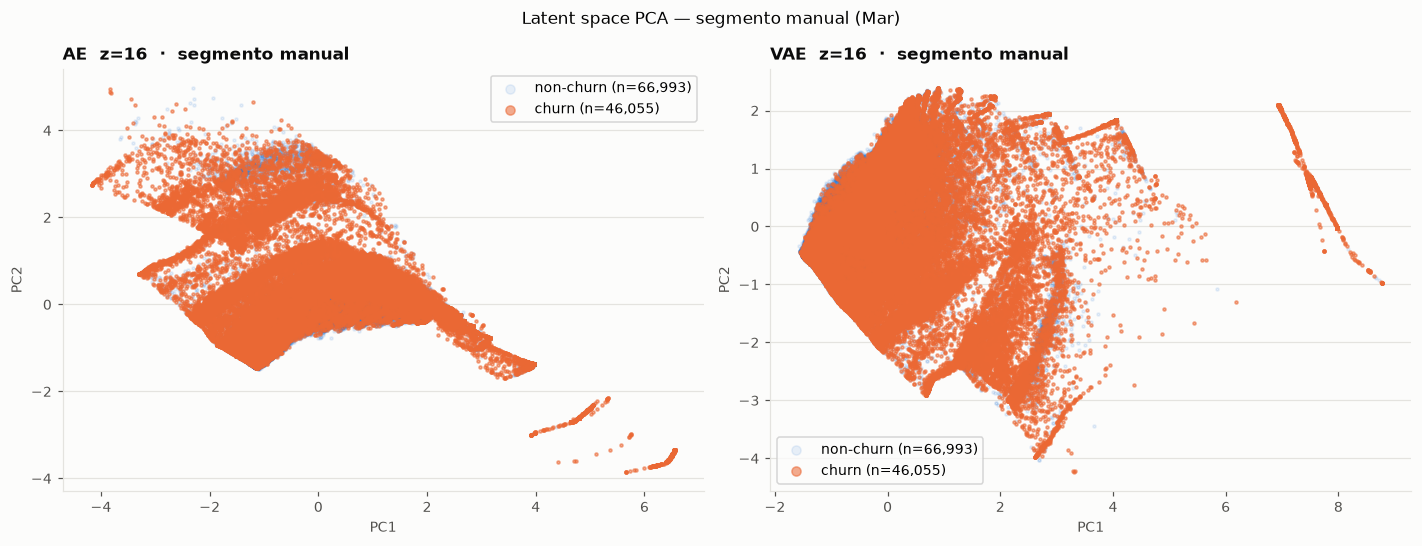

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (model_name, model) in zip(axes, [("AE", best_ae), ("VAE", best_vae)]):
    z_all = encode_all(model, x_num_mar_man, x_cat_mar_man)

    z2    = PCA(n_components=2, random_state=SEED).fit_transform(z_all)
    for label, lname, color, alpha in [
        (0, "non-churn", C.COLORS["stay"],  0.10),
        (1, "churn",     C.COLORS["churn"], 0.55),
    ]:
        mask = SCENARIOS[0][3] == label

        ax.scatter(z2[mask, 0], z2[mask, 1], s=4, alpha=alpha,
                   color=color, label=f"{lname} (n={mask.sum():,})")
    z_dim = BEST_Z_AE if model_name == "AE" else BEST_Z_VAE
    ax.set_title(f"{model_name}  z={z_dim}  ·  segmento manual", loc="left")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=9, markerscale=3)

plt.suptitle("Latent space PCA — segmento manual (Mar)", fontsize=11)
plt.tight_layout()
C.save_fig(fig, "15_latent_pca")
plt.show()

## 13. Tabla resumen final

In [17]:
print("=" * 80)
print("Anomaly detection — resultados finales")
print("Umbral: best-F1 sobre segmento manual, aplicado a los 3 escenarios")
print("=" * 80)

for model_name in ["AE", "VAE"]:
    print(f"\n── {model_name} ────────────────────────────────────────────────────")
    sub = results_df[results_df["model"] == model_name][SHOW].round(4)
    print(sub.to_string(index=False))

print()
print("Feature set:")
print(f"  CAT ({len(CAT)}): {CAT}")
print(f"  BIN ({len(BIN)}): {BIN}")
print(f"  NUM ({len(NUM)}): {NUM}")
print()
print("Referencia — XGBoost supervisado (EDA 09):")
print("  Feb tune:  F1=0.5638  Precision=0.5287  Recall=0.6039  AUC=0.9009")
print("  March OOT: F1=0.5844  Precision=0.6429  Recall=0.5357  AUC=0.8689")

Anomaly detection — resultados finales
Umbral: best-F1 sobre segmento manual, aplicado a los 3 escenarios

── AE ────────────────────────────────────────────────────
model    escenario  roc_auc  avg_prec    f1  precision  recall  flag_rate
   AE Mar · manual   0.6538    0.5797 0.597     0.4569  0.8612     0.7679

── VAE ────────────────────────────────────────────────────
model    escenario  roc_auc  avg_prec     f1  precision  recall  flag_rate
  VAE Mar · manual   0.5573    0.4985 0.5789     0.4074     1.0     0.9999

Feature set:
  CAT (1): ['expiry_month']
  BIN (0): []
  NUM (6): ['longest_gap', 'latest_gap_ratio', 'renewal_frequency', 'active_days_90', 'active_days_30', 'active_weeks_90']

Referencia — XGBoost supervisado (EDA 09):
  Feb tune:  F1=0.5638  Precision=0.5287  Recall=0.6039  AUC=0.9009
  March OOT: F1=0.5844  Precision=0.6429  Recall=0.5357  AUC=0.8689


## 14. Analysis

**Fill in after running:**

**Gap ratio (section 8):** Was the mean error of churners significantly higher than non-churners?
A ratio > 1.5x indicates the features create usable separation. If < 1.2x, the distributions still
overlap too much regardless of threshold choice.

**F1 vs supervised baseline:**
- The supervised XGBoost achieves F1=0.56 (Feb) / F1=0.58 (March) using 20 features.
- For the unsupervised model to be competitive, it needs F1 > 0.45 — otherwise the feature
  redesign didn't help enough and the signal is fundamentally supervisable but not anomaly-detectable.

**Binary indicators (section 2):** Which binary features showed the highest churn ratio?
`is_manual_and_silent` and `is_cancel_state` are expected to show 10x+ ratios.
If they don't, the training data may have different state label distributions than expected.

**PCA (section 12):** Is there a visible cluster of churners now? With the anomaly-oriented features,
churners should appear in the periphery of the latent space (high reconstruction error region)
rather than mixed uniformly with non-churners.

**Next step if F1 is still low:**
Train a separate AE only on `state='manual'` users — the manual group has the clearest
anomaly signal (listening silence → 88% churn) and training a segment-specific AE would
let the model learn exactly what 'normal manual user' looks like.

---
**Previous:** `14_february_only_split.ipynb`